In [511]:
from typing_extensions import LiteralString
import pandas as pd
import numpy as np
import matplotlib as mtp
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import re
import ast

Load ISEF file

In [512]:
isef_raw = pd.read_csv("isef-database.csv", engine='python', on_bad_lines='skip')
isef_raw.head()

,title,category,year,schools,abstract,country,State,Province,awards
0,Dynamic Response of a Human Neck Replica to Ax...,Energy: Physical,2014,set(),Purpose: A human neck replica was made to simu...,United States of America,MN,NaN,['nan']
1,The Effect of Nutrient Solution Concentration ...,Physics and Astronomy,2014,set(),Studies comparing the mineral nutrition of hyd...,United States of America,UT,NaN,['nan']
2,Do Air Root Pruning Pots Accelerate Success in...,Physics and Astronomy,2014,set(),The purpose of my project was to determine whi...,United States of America,LA,NaN,['nan']
3,Insect-repelling Plants & New Organic Pesticide,Environmental Engineering,2014,set(),Organochlorine pesticides in agriculture are n...,United States of America,TX,NaN,['nan']
4,How Do Different Factors Affect the Accuracy o...,Earth and Environmental Sciences,2014,set(),The purpose of this experiment is to determine...,United States of America,MN,NaN,['nan']


In [513]:
#Check years and entries for loading initial dataset
print(f"ISEF: {len(isef_raw)} rows, {isef_raw.shape[1]} columns")
print(f"ISEF years: {isef_raw['year'].min()} - {isef_raw['year'].max()}")

ISEF: 14911 rows, 9 columns
ISEF years: 2014 - 2024


In [514]:
#Check column attributes and non-null
print(isef_raw.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14911 entries, 0 to 14910
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   title     14911 non-null  object
 1   category  12851 non-null  object
 2   year      14911 non-null  int64 
 3   schools   14911 non-null  object
 4   abstract  11767 non-null  object
 5   country   13332 non-null  object
 6   State     8855 non-null   object
 7   Province  1310 non-null   object
 8   awards    13332 non-null  object
dtypes: int64(1), object(8)
memory usage: 1.0+ MB
None


Data cleaning

In [515]:
#Check distribution of year attribute
print(isef_raw['year'].describe())

count    14911.000000
mean      2018.961974
std          3.174338
min       2014.000000
25%       2016.000000
50%       2019.000000
75%       2022.000000
max       2024.000000
Name: year, dtype: float64


In [516]:
#Check unique country values for the entire dataset
print(isef_raw['country'].unique())
print((isef_raw['country']).nunique())

['United States of America' 'Philippines' 'Azerbaijan' 'Puerto Rico'
 'China' 'Indonesia' 'Chinese Taipei' 'Russian Federation' 'Mexico'
 'American Samoa' 'India' nan 'Belarus' 'Slovakia' 'Czech Republic'
 'Colombia' 'China, Macao Special Administrative Region' 'Ireland' 'Peru'
 'China, Hong Kong Special Administrative Region' 'Brazil' 'Chile'
 'Ukraine' 'Romania' 'Austria' 'Egypt' 'Jordan' 'Denmark'
 'Republic of Moldova' 'Malaysia' 'Kenya' 'France' 'Hungary' 'Norway'
 'Japan' 'Thailand' 'Georgia' 'Portugal' 'Nigeria' 'Tunisia' 'Iraq'
 'Italy' 'Australia' 'Israel' 'Argentina' 'Costa Rica' 'South Africa'
 'Sri Lanka' 'Pakistan' 'Northern Ireland' 'Finland' 'Switzerland'
 'South Korea' 'Northern Mariana Islands' 'Estonia' 'Panama' 'Singapore'
 'Kuwait' 'Viet Nam' 'Netherlands' 'Bulgaria' 'Kazakhstan' 'Uruguay'
 'New Zealand' 'Palestine' 'United Kingdom' 'Canada' 'Lebanon' 'Turkey'
 'Sweden' 'Saudi Arabia' 'Poland' 'Qatar' 'Luxembourg'
 'United States Virgin Islands' 'United Arab Emirate

In [517]:
#Check unique state values for the entire dataset
print(isef_raw['State'].unique())
print(len(isef_raw['State'].unique()))
#50 states + Puerto Rico + Washington DC + N/A value

['MN' 'UT' 'LA' 'TX' 'MO' 'HI' 'FL' nan 'WY' 'OK' 'OR' 'GA' 'WI' 'AR' 'NM'
 'CO' 'KY' 'AL' 'SC' 'NE' 'OH' 'NC' 'MA' 'NJ' 'WA' 'VA' 'AK' 'NY' 'MT'
 'MD' 'IL' 'MI' 'NV' 'WV' 'CA' 'PA' 'TN' 'AZ' 'CT' 'IA' 'MS' 'RI' 'DC'
 'ME' 'SD' 'VT' 'ND' 'IN' 'KS' 'NH' 'ID' 'PR' 'VI']
53


In [518]:
#Check unique Province values for the entire dataset
print(isef_raw['Province'].unique())

[nan 'EGY-ASE' '-' 'Lima' 'Avenida Calle 26 No.57-41 Torr'
 'North Rhine-Westphalia' 'San Francisco de Calle Blancos' 'San José'
 'Sichuan' 'Quebec' 'Ontario' 'Delhi' 'Ulster' 'DKI Jakarta' 'Bavaria'
 'AV. Calle 26 No. 57-83' 'Astana, Republic avenue 134 A' 'Edo State'
 'Antioquia' 'Milano' 'Pathum Thani' 'Barcelona'
 'Lilla Frescativägen 4C, 114 18' 'Federal Capital' 'Córdoba Province'
 'Hesse' 'Ariana' 'Bangkok' 'State of Sao Paulo' 'Jakarta'
 'New South Wales' 'SP' 'Seoul' 'Egyptian Association for Scien' 'Ha Noi'
 'Delta , East & Upper Egypt' 'Rio Grande do Sul' 'Sofia' 'Suceava'
 'Tartu County' 'Lower Saxony' 'Victoria' 'HARARE' 'Kazakhstan' 'Gauteng'
 'Taipei' 'Alexandria, Egypt' 'Circuito Juan Pablo II No.2240' 'Riga'
 'DELHI' 'Tokyo' 'Chungnam-do' 'CA' 'Hamburg' 'Dublin' 'United States (1)'
 'Capital' 'Harare' 'MO' 'KY' 'NM' 'UT' 'Porto' 'United States'
 'Jerusalem' 'VA' 'SD' 'Puebla' 'Oslo' 'IA' 'Aqmola' 'NY' 'QC' 'Missouri'
 'IN' 'Singapore' 'ND' 'Bulgaria' 'Please select...'

In [519]:
# Duplicate detection
# Catches rows that appear more than once, which inflate counts.
# Use a meaningful subset of columns — title, abstract, year, country

dupes = isef_raw.duplicated(subset=["title","abstract","year","country"], keep=False)
print(f"Duplicate rows: {dupes.sum()}")
if dupes.sum() > 0:
    # Inspect a sample before deciding whether to drop or investigate
    print(isef_raw[dupes][["year","country","category","title"]].sort_values("title").head(10))

# To remove duplicates (keep first occurrence):
isef = isef_raw.drop_duplicates(subset=["title","abstract","year","country"], keep="first")
print(f"Rows after deduplication: {len(isef)} (removed {len(isef_raw)-len(isef)})")




Duplicate rows: 73
       year                   country                        category  \
3585   2016  United States of America                             NaN   
3584   2016  United States of America                             NaN   
1916   2015  United States of America                             NaN   
1917   2015  United States of America                             NaN   
8866   2020  United States of America  Biomedical and Health Sciences   
8867   2020  United States of America  Biomedical and Health Sciences   
12221  2022  United States of America          Biomedical Engineering   
12220  2022  United States of America          Biomedical Engineering   
1163   2014                   Lebanon                Energy: Chemical   
1164   2014                   Lebanon                Energy: Chemical   

                                                   title  
3585   A Nanomedicine Approach for Targeted Thrombolysis  
3584   A Nanomedicine Approach for Targeted Thrombolysis  


In [520]:
# Reveals data gaps by year for missing abstracts
null_report_abstract = (isef.groupby("year") .agg(total=("abstract","count"), #Group ISEF by year, then count each entry's abstract by year as total column
                    nulls=("abstract", lambda x: x.isna().sum()))  #Null column: count up each null value in the abstract column by year
                    .assign(pct_null=lambda d: (d["nulls"]/(d["total"]+d["nulls"])*100).round(1)) #Create percent null column to show % of projects by year that have null abstract
                    .reset_index()) #Reset index so year is workable column
print(null_report_abstract)

    year  total  nulls  pct_null
0   2014   1089    305      21.9
1   2015   1059    290      21.5
2   2016   1053    318      23.2
3   2017   1094    309      22.0
4   2018   1067    323      23.2
5   2019   1089    337      23.6
6   2020    837    190      18.5
7   2021   1173    279      19.2
8   2022   1126    274      19.6
9   2023   1063    253      19.2
10  2024   1082    263      19.6


In [521]:
#Fill empty text-type cells with "" to not produce error
isef["abstract"] = isef["abstract"].fillna("")
isef["title"] = isef["title"].fillna("")
#Create combined text column to more easily parse trends from text-type
isef["text"] = isef["title"] + " " + isef["abstract"]
#Check work
isef.head()

/tmp/ipykernel_11556/4040701490.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  isef["abstract"] = isef["abstract"].fillna("")
/tmp/ipykernel_11556/4040701490.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  isef["title"] = isef["title"].fillna("")
/tmp/ipykernel_11556/4040701490.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/panda

,title,category,year,schools,abstract,country,State,Province,awards,text
0,Dynamic Response of a Human Neck Replica to Ax...,Energy: Physical,2014,set(),Purpose: A human neck replica was made to simu...,United States of America,MN,NaN,['nan'],Dynamic Response of a Human Neck Replica to Ax...
1,The Effect of Nutrient Solution Concentration ...,Physics and Astronomy,2014,set(),Studies comparing the mineral nutrition of hyd...,United States of America,UT,NaN,['nan'],The Effect of Nutrient Solution Concentration ...
2,Do Air Root Pruning Pots Accelerate Success in...,Physics and Astronomy,2014,set(),The purpose of my project was to determine whi...,United States of America,LA,NaN,['nan'],Do Air Root Pruning Pots Accelerate Success in...
3,Insect-repelling Plants & New Organic Pesticide,Environmental Engineering,2014,set(),Organochlorine pesticides in agriculture are n...,United States of America,TX,NaN,['nan'],Insect-repelling Plants & New Organic Pesticid...
4,How Do Different Factors Affect the Accuracy o...,Earth and Environmental Sciences,2014,set(),The purpose of this experiment is to determine...,United States of America,MN,NaN,['nan'],How Do Different Factors Affect the Accuracy o...


Awards & money

In [522]:
def parse_awards(raw_award_text):
    try:
      award_list = ast.literal_eval(str(raw_award_text))
      return [item for item in award_list if str(item) != "nan"]

    except Exception:
      return []

  #Treat content of "awards" as test, then convert into a list.
  #Keep only the valid content in the awards_list
  #If an exception is thrown from missing content or wrong format, return empty list

In [523]:
isef["awards_list"] = isef["awards"].apply(parse_awards)
isef["won"] = isef["awards_list"].apply(lambda lst: len(lst) > 0)
isef.head(30)

#Create awards_list by applying parse_awards fxn on awards
#Create won column by taking the awards list for each entry, and T if contains awards


/tmp/ipykernel_11556/1344337663.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  isef["awards_list"] = isef["awards"].apply(parse_awards)
/tmp/ipykernel_11556/1344337663.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  isef["won"] = isef["awards_list"].apply(lambda lst: len(lst) > 0)


,title,category,year,schools,abstract,country,State,Province,awards,text,awards_list,won
0,Dynamic Response of a Human Neck Replica to Ax...,Energy: Physical,2014,set(),Purpose: A human neck replica was made to simu...,United States of America,MN,NaN,['nan'],Dynamic Response of a Human Neck Replica to Ax...,[],False
1,The Effect of Nutrient Solution Concentration ...,Physics and Astronomy,2014,set(),Studies comparing the mineral nutrition of hyd...,United States of America,UT,NaN,['nan'],The Effect of Nutrient Solution Concentration ...,[],False
2,Do Air Root Pruning Pots Accelerate Success in...,Physics and Astronomy,2014,set(),The purpose of my project was to determine whi...,United States of America,LA,NaN,['nan'],Do Air Root Pruning Pots Accelerate Success in...,[],False
3,Insect-repelling Plants & New Organic Pesticide,Environmental Engineering,2014,set(),Organochlorine pesticides in agriculture are n...,United States of America,TX,NaN,['nan'],Insect-repelling Plants & New Organic Pesticid...,[],False
4,How Do Different Factors Affect the Accuracy o...,Earth and Environmental Sciences,2014,set(),The purpose of this experiment is to determine...,United States of America,MN,NaN,['nan'],How Do Different Factors Affect the Accuracy o...,[],False
5,Dye Sensitized Solar Cells: New Structures and...,Engineering Mechanics,2014,set(),Although fossil fuels have the capacity to pow...,United States of America,TX,NaN,['Fourth Award of $500'],Dye Sensitized Solar Cells: New Structures and...,[Fourth Award of $500],True
6,A Novel Method for Determination of Camera Pos...,Embedded Systems,2014,set(),The method proposed here solves for the pose o...,United States of America,MO,NaN,['nan'],A Novel Method for Determination of Camera Pos...,[],False
7,Observational Detection of Solar g-mode Oscill...,Microbiology,2014,set(),,United States of America,HI,NaN,"['Third Award of $1,000']",Observational Detection of Solar g-mode Oscill...,"[Third Award of $1,000]",True
8,Synthesis of Periodic Mesoporous Organosilicas...,Plant Sciences,2014,set(),,United States of America,TX,NaN,"['Second Award of $2,000']",Synthesis of Periodic Mesoporous Organosilicas...,"[Second Award of $2,000]",True
9,A Novel Mathematical Simulation to Study the D...,Materials Science,2014,set(),"Human Immunodeficiency Virus (HIV), the virus ...",United States of America,TX,NaN,['nan'],A Novel Mathematical Simulation to Study the D...,[],False


In [524]:
def extract_award_money(award_list):
  total = 0
  for award_string in award_list:
      dollar_match = re.search(r"\$([0-9,]+)", award_string)
      if dollar_match:
          total += int(dollar_match.group(1).replace(",", ""))
  return total

  #Takes input of list from award_list
  #Counter at 0 for each project - returned at end
  #If empty list, 0 is returned
  #For each award in the project's award list, look for certain pattern
      # Exit to show literal
      # Dollar sign for money
      #Capture everything inside parentheses - digit or comma
  #If a dollar value found, update total value with capture group
    #Remove comma and convert to integer

In [525]:
isef["award_money"] = isef["awards_list"].apply(extract_award_money)
isef.head(30)

#Create award_money column in ISEF dataset by applying the extract_award_money function on the awards_list column info

/tmp/ipykernel_11556/721899891.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  isef["award_money"] = isef["awards_list"].apply(extract_award_money)


,title,category,year,schools,abstract,country,State,Province,awards,text,awards_list,won,award_money
0,Dynamic Response of a Human Neck Replica to Ax...,Energy: Physical,2014,set(),Purpose: A human neck replica was made to simu...,United States of America,MN,NaN,['nan'],Dynamic Response of a Human Neck Replica to Ax...,[],False,0
1,The Effect of Nutrient Solution Concentration ...,Physics and Astronomy,2014,set(),Studies comparing the mineral nutrition of hyd...,United States of America,UT,NaN,['nan'],The Effect of Nutrient Solution Concentration ...,[],False,0
2,Do Air Root Pruning Pots Accelerate Success in...,Physics and Astronomy,2014,set(),The purpose of my project was to determine whi...,United States of America,LA,NaN,['nan'],Do Air Root Pruning Pots Accelerate Success in...,[],False,0
3,Insect-repelling Plants & New Organic Pesticide,Environmental Engineering,2014,set(),Organochlorine pesticides in agriculture are n...,United States of America,TX,NaN,['nan'],Insect-repelling Plants & New Organic Pesticid...,[],False,0
4,How Do Different Factors Affect the Accuracy o...,Earth and Environmental Sciences,2014,set(),The purpose of this experiment is to determine...,United States of America,MN,NaN,['nan'],How Do Different Factors Affect the Accuracy o...,[],False,0
5,Dye Sensitized Solar Cells: New Structures and...,Engineering Mechanics,2014,set(),Although fossil fuels have the capacity to pow...,United States of America,TX,NaN,['Fourth Award of $500'],Dye Sensitized Solar Cells: New Structures and...,[Fourth Award of $500],True,500
6,A Novel Method for Determination of Camera Pos...,Embedded Systems,2014,set(),The method proposed here solves for the pose o...,United States of America,MO,NaN,['nan'],A Novel Method for Determination of Camera Pos...,[],False,0
7,Observational Detection of Solar g-mode Oscill...,Microbiology,2014,set(),,United States of America,HI,NaN,"['Third Award of $1,000']",Observational Detection of Solar g-mode Oscill...,"[Third Award of $1,000]",True,1000
8,Synthesis of Periodic Mesoporous Organosilicas...,Plant Sciences,2014,set(),,United States of America,TX,NaN,"['Second Award of $2,000']",Synthesis of Periodic Mesoporous Organosilicas...,"[Second Award of $2,000]",True,2000
9,A Novel Mathematical Simulation to Study the D...,Materials Science,2014,set(),"Human Immunodeficiency Virus (HIV), the virus ...",United States of America,TX,NaN,['nan'],A Novel Mathematical Simulation to Study the D...,[],False,0


In [526]:
#Check distribution of award money
isef['award_money'].describe()

,award_money
count,14873.000000
mean,913.573388
std,8842.398291
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,252000.000000


In [527]:
#Check distribution of award money for those who won awards
winners = isef[isef['won'] == True]
winners['award_money'].describe()

,award_money
count,3831.000000
mean,3546.744192
std,17154.144024
min,0.000000
25%,500.000000
50%,1000.000000
75%,2000.000000
max,252000.000000


In [528]:
##CHECK AWARDS WHERE AWARD MONEY > 2000
  #How many? and What is the range? What are grand prizes?
isef['top_75'] = np.where(isef['award_money'] > 2000, 1, 0)
print(len(isef[isef['top_75'] == 1]))
top_75_pct = isef[isef['top_75'] == 1]
print(top_75_pct['award_money'].describe())

722
count       722.00000
mean      15041.00000
std       37397.32546
min        2125.00000
25%        3500.00000
50%        5000.00000
75%       10000.00000
max      252000.00000
Name: award_money, dtype: float64


/tmp/ipykernel_11556/2476202575.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  isef['top_75'] = np.where(isef['award_money'] > 2000, 1, 0)


In [529]:
#For projects that won over 10,0000 (top 75% of previous check), check distribution
isef['over_10k'] = np.where(isef['award_money'] > 10000, 1, 0)
print(len(isef[isef['over_10k'] == 1]))
over_10k_wins = isef[isef['over_10k'] == 1]
print(over_10k_wins['award_money'].describe())

125
count       125.000000
mean      62492.800000
std       73228.041601
min       10500.000000
25%       15000.000000
50%       24650.000000
75%       53800.000000
max      252000.000000
Name: award_money, dtype: float64


/tmp/ipykernel_11556/1822718894.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  isef['over_10k'] = np.where(isef['award_money'] > 10000, 1, 0)


In [530]:
#For projects that won over 50,000 (top 75% of previous check), check distribution
isef['over_50k'] = np.where(isef['award_money'] > 50000, 1, 0)
print(len(isef[isef['over_50k'] == 1]))
over_50k_wins = isef[isef['over_50k'] == 1]
print(over_50k_wins['award_money'].describe())

59
count        59.000000
mean     114543.220339
std       78854.508354
min       52000.000000
25%       52000.000000
50%       54000.000000
75%      199500.000000
max      252000.000000
Name: award_money, dtype: float64


/tmp/ipykernel_11556/498842425.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  isef['over_50k'] = np.where(isef['award_money'] > 50000, 1, 0)


In [531]:
def award_tiers(dollar_amount):
  if dollar_amount == 0:
    return "None"
  elif dollar_amount <= 500:
      return "Tier 1"
  elif dollar_amount <= 1000:
    return "Tier 2"
  elif dollar_amount <= 2000:
    return "Tier 3"
  elif dollar_amount <= 5000:
    return "Tier 4"
  elif dollar_amount <= 10000:
    return "Tier 5"
  elif dollar_amount <= 25000:
    return "Tier 6"
  elif dollar_amount <= 50000:
    return "Tier 7"
  elif dollar_amount <= 100000:
    return "Tier 8"
  else:
    return "Tier 9"


#Define tiers of awards based on money received

In [532]:
isef["award_tier"] = isef["award_money"].apply(award_tiers)
isef.head(30)

 #Create award_tier column in ISEF dataset by applying award_tiers function on award_money column list info

/tmp/ipykernel_11556/572994153.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  isef["award_tier"] = isef["award_money"].apply(award_tiers)


,title,category,year,schools,abstract,country,State,Province,awards,text,awards_list,won,award_money,top_75,over_10k,over_50k,award_tier
0,Dynamic Response of a Human Neck Replica to Ax...,Energy: Physical,2014,set(),Purpose: A human neck replica was made to simu...,United States of America,MN,NaN,['nan'],Dynamic Response of a Human Neck Replica to Ax...,[],False,0,0,0,0,None
1,The Effect of Nutrient Solution Concentration ...,Physics and Astronomy,2014,set(),Studies comparing the mineral nutrition of hyd...,United States of America,UT,NaN,['nan'],The Effect of Nutrient Solution Concentration ...,[],False,0,0,0,0,None
2,Do Air Root Pruning Pots Accelerate Success in...,Physics and Astronomy,2014,set(),The purpose of my project was to determine whi...,United States of America,LA,NaN,['nan'],Do Air Root Pruning Pots Accelerate Success in...,[],False,0,0,0,0,None
3,Insect-repelling Plants & New Organic Pesticide,Environmental Engineering,2014,set(),Organochlorine pesticides in agriculture are n...,United States of America,TX,NaN,['nan'],Insect-repelling Plants & New Organic Pesticid...,[],False,0,0,0,0,None
4,How Do Different Factors Affect the Accuracy o...,Earth and Environmental Sciences,2014,set(),The purpose of this experiment is to determine...,United States of America,MN,NaN,['nan'],How Do Different Factors Affect the Accuracy o...,[],False,0,0,0,0,None
5,Dye Sensitized Solar Cells: New Structures and...,Engineering Mechanics,2014,set(),Although fossil fuels have the capacity to pow...,United States of America,TX,NaN,['Fourth Award of $500'],Dye Sensitized Solar Cells: New Structures and...,[Fourth Award of $500],True,500,0,0,0,Tier 1
6,A Novel Method for Determination of Camera Pos...,Embedded Systems,2014,set(),The method proposed here solves for the pose o...,United States of America,MO,NaN,['nan'],A Novel Method for Determination of Camera Pos...,[],False,0,0,0,0,None
7,Observational Detection of Solar g-mode Oscill...,Microbiology,2014,set(),,United States of America,HI,NaN,"['Third Award of $1,000']",Observational Detection of Solar g-mode Oscill...,"[Third Award of $1,000]",True,1000,0,0,0,Tier 2
8,Synthesis of Periodic Mesoporous Organosilicas...,Plant Sciences,2014,set(),,United States of America,TX,NaN,"['Second Award of $2,000']",Synthesis of Periodic Mesoporous Organosilicas...,"[Second Award of $2,000]",True,2000,0,0,0,Tier 3
9,A Novel Mathematical Simulation to Study the D...,Materials Science,2014,set(),"Human Immunodeficiency Virus (HIV), the virus ...",United States of America,TX,NaN,['nan'],A Novel Mathematical Simulation to Study the D...,[],False,0,0,0,0,None


In [533]:

# Based on the full audit, exclude 2014, 2015, 2016 from category-level work.
# Use 2017-2024 for all category trend analysis.
#Remove 2020 and 2024 for award analysis

#Create holders for valid year ranges for eahc purpose
CAT_YEARS = [2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]
AWARD_YEARS= [2017, 2018, 2019, 2021, 2022, 2023]

#Create category work dataset with valid category entries
isef_catwork = isef[isef["year"].isin(CAT_YEARS) &
                       isef["category"].notna()].copy()

print(f"\nRows in category analysis: {len(isef_catwork)}")

#Create award work dataset with valid category entries
isef_awardyrs = isef[isef["year"].isin(AWARD_YEARS) &
                       isef["category"].notna()].copy()

print(f"Rows in award analysis: {len(isef_awardyrs)}")


Rows in category analysis: 10759
Rows in award analysis: 8387


In [534]:
#Reset winners dataset to only competition years
winners = isef_awardyrs[isef_awardyrs['won'] == True]

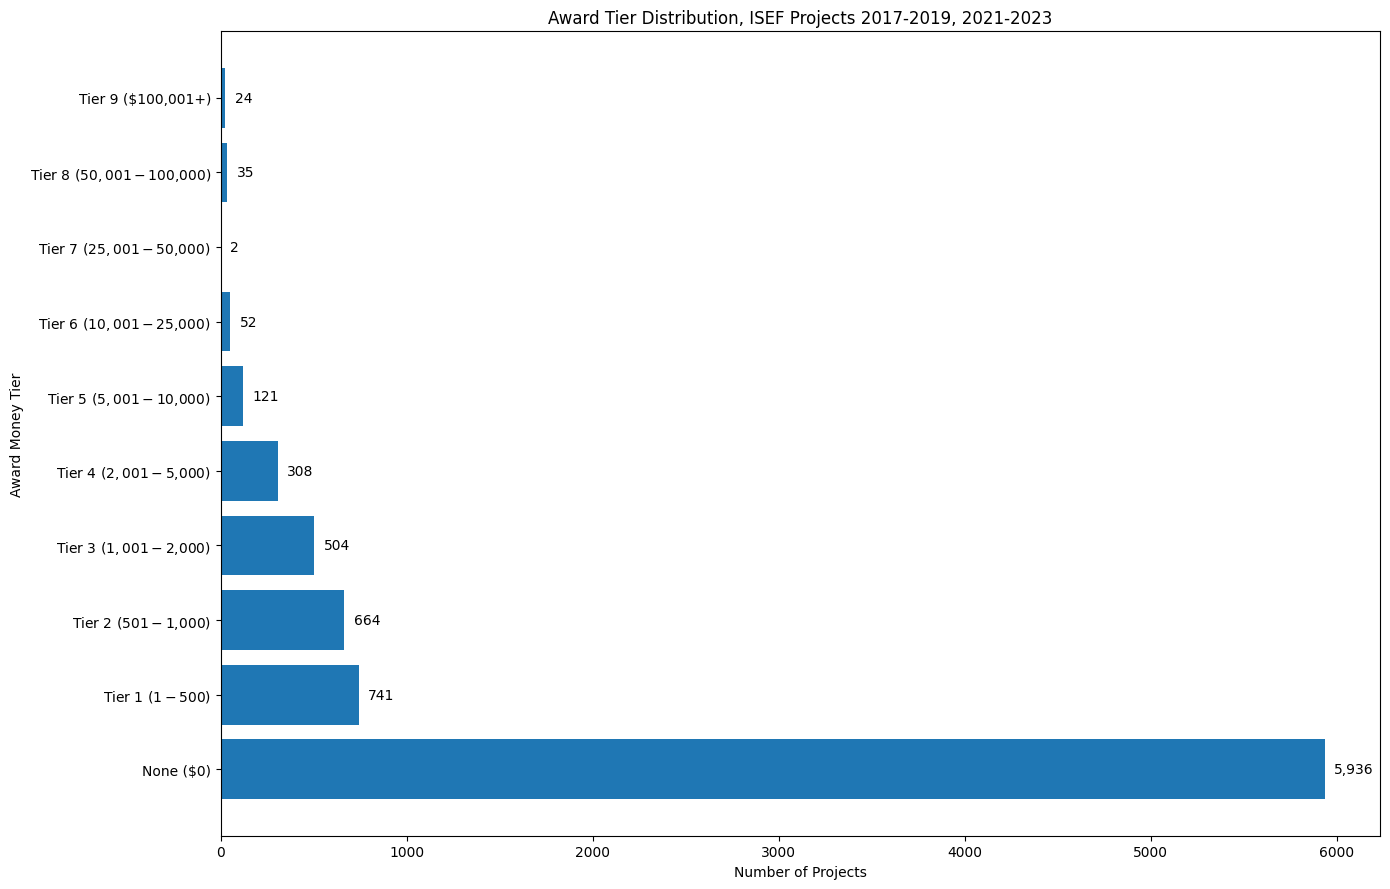

In [535]:
#Gather value counts for award tiers
award_tier_counts = isef_awardyrs["award_tier"].value_counts()

# Tier order should be logical order
tier_order = ["None", "Tier 1", "Tier 2", "Tier 3", "Tier 4", "Tier 5", "Tier 6", "Tier 7", "Tier 8", "Tier 9"]

# Reindex the counts to match the logical order, filling missing tiers with 0
award_tier_counts = award_tier_counts.reindex(tier_order, fill_value=0)

# Create descriptive labels for the y-axis including monetary values
y_labels_with_values = []
for tier in tier_order:
    if tier == "None":
        y_labels_with_values.append(f"{tier} ($0)")
    elif tier == "Tier 1":
        y_labels_with_values.append(f"{tier} ($1 - $500)")
    elif tier == "Tier 2":
        y_labels_with_values.append(f"{tier} ($501 - $1,000)")
    elif tier == "Tier 3":
        y_labels_with_values.append(f"{tier} ($1,001 - $2,000)")
    elif tier == "Tier 4":
        y_labels_with_values.append(f"{tier} ($2,001 - $5,000)")
    elif tier == "Tier 5":
        y_labels_with_values.append(f"{tier} ($5,001 - $10,000)")
    elif tier == "Tier 6":
        y_labels_with_values.append(f"{tier} ($10,001 - $25,000)")
    elif tier == "Tier 7":
        y_labels_with_values.append(f"{tier} ($25,001 - $50,000)")
    elif tier == "Tier 8":
        y_labels_with_values.append(f"{tier} ($50,001 - $100,000)")
    elif tier == "Tier 9":
        y_labels_with_values.append(f"{tier} ($100,001+)")

# Create the horizontal bar plot
plt.figure(figsize=(14, 9))
bars = plt.barh(y_labels_with_values, award_tier_counts.values)
plt.title("Award Tier Distribution, ISEF Projects 2017-2019, 2021-2023")
plt.xlabel("Number of Projects")
plt.ylabel("Award Money Tier")

# Add data labels to the bars
#For eahc bar object, get the numerical value that determines how long the bar is
for bar in bars:
    width = bar.get_width()
    plt.text(width + 50, bar.get_y() + bar.get_height()/2, f'{int(width):,}', va='center')
    #Apply text label to the right of where bar ends and at vertical center of bar
    #Text is the width value as an integer with comma separators
    #USe vertical alignment
plt.tight_layout()
plt.show()

In [536]:
winners["award_tier"] = winners["award_money"].apply(award_tiers)
winners.head(30)

#Add award_tiers to dataset of just winners

/tmp/ipykernel_11556/1458286871.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  winners["award_tier"] = winners["award_money"].apply(award_tiers)


,title,category,year,schools,abstract,country,State,Province,awards,text,awards_list,won,award_money,top_75,over_10k,over_50k,award_tier
4128,Epigenetic and Biotransformation Effects of Ho...,Cellular and Molecular Biology,2017,set(),"The practice of smoking hookah, a traditional ...",United States of America,LA,NaN,"['Third Award of $1,000', 'National Institute ...",Epigenetic and Biotransformation Effects of Ho...,"[Third Award of $1,000, National Institute on ...",True,3500,1,0,0,Tier 4
4129,The Effect of Sodium Chloride on Hybrid Taxodi...,Plant Sciences,2017,set(),Saltwater intrusion is a major cause of erosio...,United States of America,LA,NaN,"['Second Award of $2,000']",The Effect of Sodium Chloride on Hybrid Taxodi...,"[Second Award of $2,000]",True,2000,0,0,0,Tier 3
4133,Mutasd! - Interactive Software for Learning an...,Systems Software,2017,set(),The integration of deaf-mute people in our eve...,Hungary,NaN,NaN,['Fourth Award of $500'],Mutasd! - Interactive Software for Learning an...,[Fourth Award of $500],True,500,0,0,0,Tier 1
4134,Numerical Methods of Raytracing in Curved Spac...,Physics and Astronomy,2017,set(),,Poland,NaN,-,['Fourth Award of $500'],Numerical Methods of Raytracing in Curved Spac...,[Fourth Award of $500],True,500,0,0,0,Tier 1
4140,Galectin-4 and the Functions of N- and C- Term...,Cellular and Molecular Biology,2017,set(),The purpose of this project was to characteriz...,United States of America,GA,NaN,['Fourth Award of $500'],Galectin-4 and the Functions of N- and C- Term...,[Fourth Award of $500],True,500,0,0,0,Tier 1
4143,Study and Modeling of Pressure and Temperature...,Earth and Environmental Sciences,2017,set(),,France,NaN,NaN,"['Third Award of $1,000', 'Geological Society ...",Study and Modeling of Pressure and Temperature...,"[Third Award of $1,000, Geological Society of ...",True,2250,1,0,0,Tier 4
4153,Pathogenic Yeast Candida parapsilosis and Its ...,Biochemistry,2017,set(),The yeast Candida parapsilosis is a so-called ...,Czech Republic,NaN,NaN,['Fourth Award of $500'],Pathogenic Yeast Candida parapsilosis and Its ...,[Fourth Award of $500],True,500,0,0,0,Tier 1
4155,"The Morality of ""Larks"" and ""Owls"": The Relati...",Behavioral and Social Sciences,2017,set(),"Decision-making is affected by many factors, i...",Belgium,NaN,NaN,['American Psychological Association: Certific...,"The Morality of ""Larks"" and ""Owls"": The Relati...",[American Psychological Association: Certifica...,True,0,0,0,0,None
4160,Identification of dsRNA Mycoviruses in Plant-P...,Plant Sciences,2017,set(),Fusarium oxysporum is a plant pathogenic fungu...,Czech Republic,NaN,NaN,"['Second Award of $2,000']",Identification of dsRNA Mycoviruses in Plant-P...,"[Second Award of $2,000]",True,2000,0,0,0,Tier 3
4161,The Role of RAD51 Mutation in Cancer Development,Biochemistry,2017,set(),Genome instability is a major driving force of...,Czech Republic,NaN,NaN,"['Intel ISEF Best of Category Award of $5,000']",The Role of RAD51 Mutation in Cancer Developme...,"[Intel ISEF Best of Category Award of $5,000]",True,5000,1,0,0,Tier 4


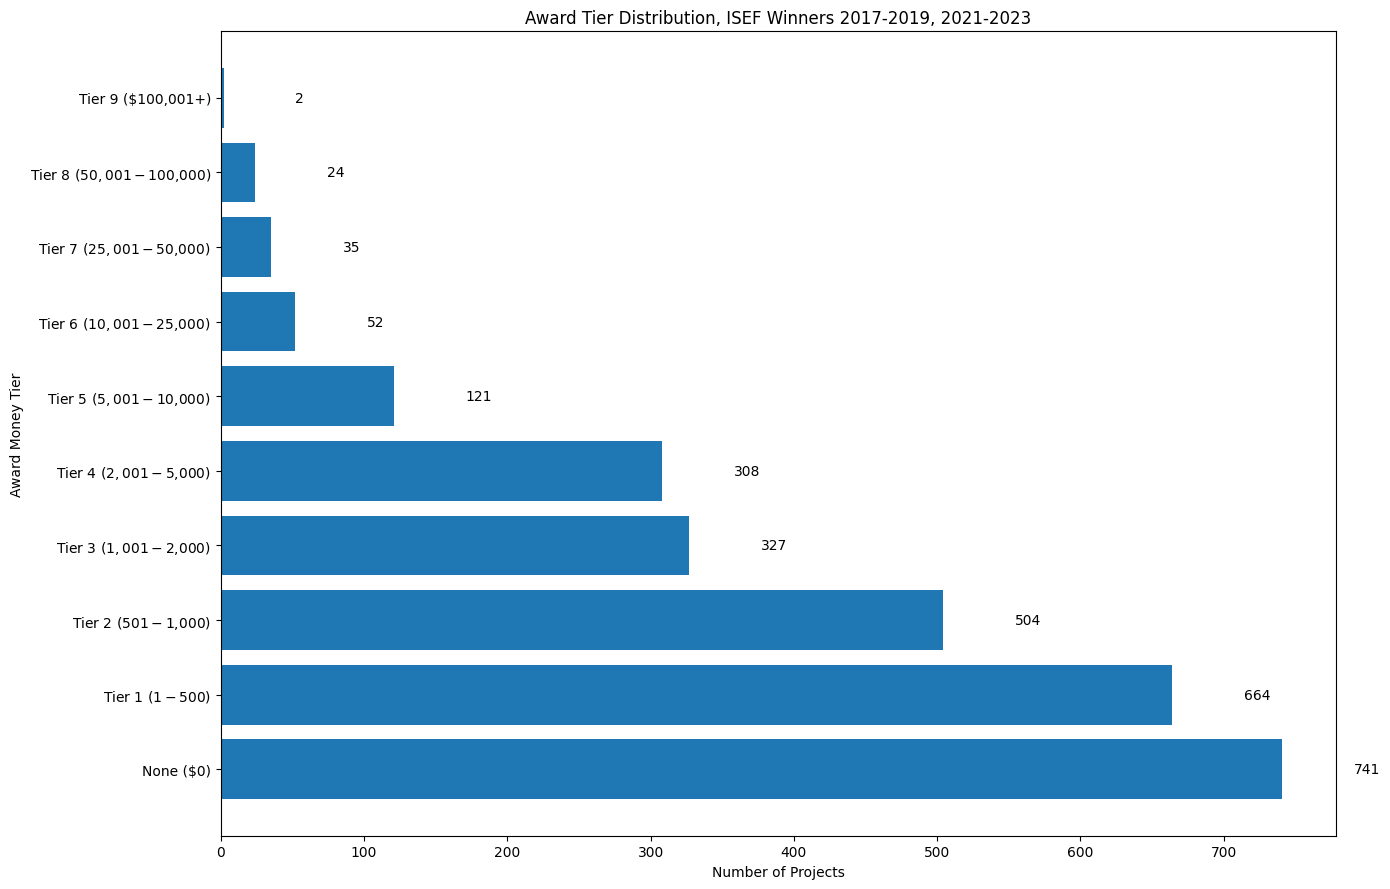

In [537]:
#Gather value counts for award tiers for only those who won awards
award_tier_counts_win = winners["award_tier"].value_counts()

plt.figure(figsize=(14, 9))
bars = plt.barh(y_labels_with_values, award_tier_counts_win.values)

plt.title("Award Tier Distribution, ISEF Winners 2017-2019, 2021-2023")
plt.xlabel("Number of Projects")
plt.ylabel("Award Money Tier")

#For eahc bar object, get the numerical value that determines how long the bar is
for bar in bars:
    width = bar.get_width()
    plt.text(width + 50, bar.get_y() + bar.get_height()/2, f'{int(width):,}', va='center')
    #Apply text label to the right of where bar ends and at vertical center of bar
    #Text is the width value as an integer with comma separators
    #USe vertical alignment

plt.tight_layout()
plt.show()

Category processing
1. What years might be missing large gaps of important information? (We already checked abstract, so check category)
2. Check how many unique categories exist per year (check changes in category list and missing information)
3. Which years were missing which categories? Which categories were not present in which years?
4. Check for duplicate projects.

In [538]:
# Null audit: reveal data gaps by year for missing category

null_report_category = (isef.groupby("year").agg(total=("category","count"), #Group by year, total column is count of projects by checking category
                    nulls=("category", lambda x: x.isna().sum())) #Nulls column is sum of number of projects where category returns null
                                                                  #Category can be done now but abstract had to happen before filling with ""
                    .assign(pct_null=lambda d: (d["nulls"]/(d["total"]+d["nulls"])*100).round(1)) #Return percent of projects per year that have null val for category to 0.1
                    .reset_index()) #Reset index so year is workable column
print(null_report_category)

    year  total  nulls  pct_null
0   2014   1394      0       0.0
1   2015    426    923      68.4
2   2016    243   1128      82.3
3   2017   1403      0       0.0
4   2018   1390      0       0.0
5   2019   1426      0       0.0
6   2020   1027      0       0.0
7   2021   1452      0       0.0
8   2022   1400      0       0.0
9   2023   1316      0       0.0
10  2024   1345      0       0.0


In [539]:
# Category name inventory - every unique category per year
# Why? Changing categorization by ISEF, especially in 2014 - 2016 range

cat_by_year = (isef.dropna(subset=["category"]) #Remove entries with null category
               .groupby("year")["category"] #Groyp by year, then select only category info from year-based groups
               .unique() #On the category info for each year group, return array of unique values
               .reset_index()) #Return index to normal column so year is workable
cat_by_year["n_categories"] = cat_by_year["category"].apply(len) #Number of categories column is how many categories in unique category array by year
cat_by_year["categories"] = cat_by_year["category"].apply(sorted) #Alphabetically sorted list
print(cat_by_year[["year","n_categories"]].to_string()) #Return all info


    year  n_categories
0   2014            17
1   2015             9
2   2016             9
3   2017            22
4   2018            22
5   2019            22
6   2020            21
7   2021            21
8   2022            21
9   2023            21
10  2024            22


In [540]:
# Presence matrix year x category
# Every category should run every year if that category was part of ISEF's list

presence = (isef.dropna(subset=["category"]) #Remove entries with null category
            .groupby(["year","category"]) #Group by year and category (2017 Biology is different than 2020 Biology and 2017 Math for ex.)
            .size() #Count how many rows fall into the yearxcategory bucket
            .unstack(fill_value=0)) #Make category a column, and fill any missing values with 0

# Flag any cell that is zero
zero_flags = (presence == 0) #New dataframe with T/F showing missing category by year
problem_categories = zero_flags.columns[zero_flags.any()].tolist() #Collapse each category down to single value - if missing in any year, then it has absence issues
print("Categories with at least one zero year:", problem_categories) #Print list of categories with absence issues
print(len(problem_categories)) #Count how many problem categories

# Print only the flagged columns for review
review = presence[problem_categories] #DF with just defined problem categories from presence matrix

Categories with at least one zero year: ['Animal Sciences', 'Behavioral and Social Sciences', 'Biochemistry', 'Biomedical Engineering', 'Cellular and Molecular Biology', 'Chemistry', 'Earth and Environmental Sciences', 'Embedded Systems', 'Energy: Chemical', 'Energy: Physical', 'Energy: Sustainable Materials and Design', 'Engineering Mechanics', 'Engineering Technology: Statics & Dynamics', 'Environmental Engineering', 'Materials Science', 'Mathematics', 'Microbiology', 'Physics and Astronomy', 'Plant Sciences', 'Robotics and Intelligent Machines', 'Technology Enhances the Arts', 'Translational Medical Science']
22


In [541]:
review
#Categories - only those that have at least one missing year
#Otherwise, how many projects were in that category that year

#Animal, Behavioral, Biochem, Biomed, translational medical didn't exist until 2015
#2015 - 2016 are a mess, most categories missing - not just a result of restructure, this is a huge data integrity gap
#Engineering Tech created 2022 while mechanics eliminated
#Energy Chem and Physical eliminated as of 2020, where sustainable materials was introduced
#Enchancing arts intrpduced in 2024


category,Animal Sciences,Behavioral and Social Sciences,Biochemistry,Biomedical Engineering,Cellular and Molecular Biology,Chemistry,Earth and Environmental Sciences,Embedded Systems,Energy: Chemical,Energy: Physical,...,Engineering Technology: Statics & Dynamics,Environmental Engineering,Materials Science,Mathematics,Microbiology,Physics and Astronomy,Plant Sciences,Robotics and Intelligent Machines,Technology Enhances the Arts,Translational Medical Science
year,,,,,,,,,,,,,,,,,,,,,
2014,0,0,0,0,26,84,75,75,124,111,...,0,71,106,167,45,93,104,63,0,0
2015,5,10,37,115,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,54
2016,4,6,24,31,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,50
2017,63,64,37,82,58,73,93,52,49,40,...,0,83,80,55,68,60,64,48,0,62
2018,70,61,44,76,44,69,85,58,41,32,...,0,92,58,53,70,89,70,69,0,59
2019,55,51,43,74,60,71,86,46,45,28,...,0,102,75,43,87,70,75,76,0,55
2020,43,46,26,50,38,50,63,31,0,0,...,0,55,49,38,52,56,63,52,0,55
2021,64,84,33,105,37,72,126,35,0,0,...,0,89,49,48,58,79,52,89,0,62
2022,75,72,41,81,41,73,90,41,0,0,...,82,98,55,39,63,74,54,85,0,66


In [542]:
print(review.to_string())

category  Animal Sciences  Behavioral and Social Sciences  Biochemistry  Biomedical Engineering  Cellular and Molecular Biology  Chemistry  Earth and Environmental Sciences  Embedded Systems  Energy: Chemical  Energy: Physical  Energy: Sustainable Materials and Design  Engineering Mechanics  Engineering Technology: Statics & Dynamics  Environmental Engineering  Materials Science  Mathematics  Microbiology  Physics and Astronomy  Plant Sciences  Robotics and Intelligent Machines  Technology Enhances the Arts  Translational Medical Science
year                                                                                                                                                                                                                                                                                                                                                                                                                                                                    

In [543]:
print(isef_catwork["category"].unique())
print(isef_catwork['category'].nunique())
#Which categories and how many
#Create broad category map
CATEGORY_MAP = {
    "Physics & Energy": ["Energy: Physical", "Physics and Astronomy", "Energy: Chemical", "Energy: Sustainable Materials and Design" ],
    "Earth & Environment": ['Environmental Engineering', 'Earth and Environmental Sciences', 'Plant Sciences'],
    "Engineering & Physical Science": ['Engineering Mechanics', 'Embedded Systems', 'Materials Science', "Robotics and Intelligent Machines", "Biomedical Engineering", "Engineering Technology: Statics & Dynamics", "Technology Enhances the Arts" ],
    "Life Sciences": ['Microbiology', 'Computational Biology and Bioinformatics', "Cellular and Molecular Biology", "Chemistry", "Biomedical and Health Sciences", "Biochemistry", "Translational Medical Science", "Behavioral and Social Sciences", "Animal Sciences"],
    "Computing & Math": ['Systems Software', 'Mathematics']
}

['Physics and Astronomy' 'Cellular and Molecular Biology' 'Plant Sciences'
 'Chemistry' 'Mathematics' 'Systems Software' 'Materials Science'
 'Biomedical and Health Sciences' 'Environmental Engineering'
 'Embedded Systems' 'Biochemistry' 'Earth and Environmental Sciences'
 'Translational Medical Science' 'Behavioral and Social Sciences'
 'Engineering Mechanics' 'Microbiology' 'Biomedical Engineering'
 'Computational Biology and Bioinformatics' 'Energy: Physical'
 'Robotics and Intelligent Machines' 'Animal Sciences' 'Energy: Chemical'
 'Energy: Sustainable Materials and Design'
 'Engineering Technology: Statics & Dynamics'
 'Technology Enhances the Arts']
25


In [544]:
def broad_categorize(specific_category):
    for broad_name, specific_list in CATEGORY_MAP.items():
        if specific_category in specific_list:
            return broad_name
    return "Other"

#If find your category in the items in CATEGORY MAP, return the broad_name it corresponds to

In [545]:
isef_catwork["general_category"] = isef_catwork["category"].apply(broad_categorize)
isef_catwork.head(30)

#Create general_category using broad_categorize

,title,category,year,schools,abstract,country,State,Province,awards,text,awards_list,won,award_money,top_75,over_10k,over_50k,award_tier,general_category
4127,The Thermoelectrically Refrigerated Cloud Chamber,Physics and Astronomy,2017,set(),A diffusion cloud chamber is a detector of ion...,Czech Republic,NaN,NaN,['nan'],The Thermoelectrically Refrigerated Cloud Cham...,[],False,0,0,0,0,None,Physics & Energy
4128,Epigenetic and Biotransformation Effects of Ho...,Cellular and Molecular Biology,2017,set(),"The practice of smoking hookah, a traditional ...",United States of America,LA,NaN,"['Third Award of $1,000', 'National Institute ...",Epigenetic and Biotransformation Effects of Ho...,"[Third Award of $1,000, National Institute on ...",True,3500,1,0,0,Tier 4,Life Sciences
4129,The Effect of Sodium Chloride on Hybrid Taxodi...,Plant Sciences,2017,set(),Saltwater intrusion is a major cause of erosio...,United States of America,LA,NaN,"['Second Award of $2,000']",The Effect of Sodium Chloride on Hybrid Taxodi...,"[Second Award of $2,000]",True,2000,0,0,0,Tier 3,Earth & Environment
4130,"How to Stop the ""Walking"" Protein?",Chemistry,2017,set(),An effective method to stop a tumor growth is ...,Russian Federation,NaN,NaN,['nan'],"How to Stop the ""Walking"" Protein? An effectiv...",[],False,0,0,0,0,None,Life Sciences
4131,Bijections between Graphs and Tilings with Wal...,Mathematics,2017,set(),"In the current research, we consider tilings w...",Bulgaria,NaN,NaN,['nan'],Bijections between Graphs and Tilings with Wal...,[],False,0,0,0,0,None,Computing & Math
4132,Linux Processes' Memory Visualization,Systems Software,2017,set(),Linux processes’ memory visualization (MemVis)...,Bulgaria,NaN,NaN,['nan'],Linux Processes' Memory Visualization Linux pr...,[],False,0,0,0,0,None,Computing & Math
4133,Mutasd! - Interactive Software for Learning an...,Systems Software,2017,set(),The integration of deaf-mute people in our eve...,Hungary,NaN,NaN,['Fourth Award of $500'],Mutasd! - Interactive Software for Learning an...,[Fourth Award of $500],True,500,0,0,0,Tier 1,Computing & Math
4134,Numerical Methods of Raytracing in Curved Spac...,Physics and Astronomy,2017,set(),,Poland,NaN,-,['Fourth Award of $500'],Numerical Methods of Raytracing in Curved Spac...,[Fourth Award of $500],True,500,0,0,0,Tier 1,Physics & Energy
4135,"On the Glow: Assessing the Luminosity, Durabil...",Materials Science,2017,set(),,United States of America,LA,NaN,['nan'],"On the Glow: Assessing the Luminosity, Durabil...",[],False,0,0,0,0,None,Engineering & Physical Science
4136,Polymeric Mortar of Brick and Block Laying: A ...,Materials Science,2017,set(),,Brazil,NaN,NaN,['nan'],Polymeric Mortar of Brick and Block Laying: A ...,[],False,0,0,0,0,None,Engineering & Physical Science


In [546]:
isef_catwork.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10759 entries, 4127 to 14910
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   title             10759 non-null  object
 1   category          10759 non-null  object
 2   year              10759 non-null  int64 
 3   schools           10759 non-null  object
 4   abstract          10759 non-null  object
 5   country           9259 non-null   object
 6   State             6127 non-null   object
 7   Province          1308 non-null   object
 8   awards            9259 non-null   object
 9   text              10759 non-null  object
 10  awards_list       10759 non-null  object
 11  won               10759 non-null  bool  
 12  award_money       10759 non-null  int64 
 13  top_75            10759 non-null  int64 
 14  over_10k          10759 non-null  int64 
 15  over_50k          10759 non-null  int64 
 16  award_tier        10759 non-null  object
 17  general_catego

In [547]:
isef_awardyrs["general_category"] = isef_awardyrs["category"].apply(broad_categorize)
isef_awardyrs.head(30)

#Create general category in award years as well

,title,category,year,schools,abstract,country,State,Province,awards,text,awards_list,won,award_money,top_75,over_10k,over_50k,award_tier,general_category
4127,The Thermoelectrically Refrigerated Cloud Chamber,Physics and Astronomy,2017,set(),A diffusion cloud chamber is a detector of ion...,Czech Republic,NaN,NaN,['nan'],The Thermoelectrically Refrigerated Cloud Cham...,[],False,0,0,0,0,None,Physics & Energy
4128,Epigenetic and Biotransformation Effects of Ho...,Cellular and Molecular Biology,2017,set(),"The practice of smoking hookah, a traditional ...",United States of America,LA,NaN,"['Third Award of $1,000', 'National Institute ...",Epigenetic and Biotransformation Effects of Ho...,"[Third Award of $1,000, National Institute on ...",True,3500,1,0,0,Tier 4,Life Sciences
4129,The Effect of Sodium Chloride on Hybrid Taxodi...,Plant Sciences,2017,set(),Saltwater intrusion is a major cause of erosio...,United States of America,LA,NaN,"['Second Award of $2,000']",The Effect of Sodium Chloride on Hybrid Taxodi...,"[Second Award of $2,000]",True,2000,0,0,0,Tier 3,Earth & Environment
4130,"How to Stop the ""Walking"" Protein?",Chemistry,2017,set(),An effective method to stop a tumor growth is ...,Russian Federation,NaN,NaN,['nan'],"How to Stop the ""Walking"" Protein? An effectiv...",[],False,0,0,0,0,None,Life Sciences
4131,Bijections between Graphs and Tilings with Wal...,Mathematics,2017,set(),"In the current research, we consider tilings w...",Bulgaria,NaN,NaN,['nan'],Bijections between Graphs and Tilings with Wal...,[],False,0,0,0,0,None,Computing & Math
4132,Linux Processes' Memory Visualization,Systems Software,2017,set(),Linux processes’ memory visualization (MemVis)...,Bulgaria,NaN,NaN,['nan'],Linux Processes' Memory Visualization Linux pr...,[],False,0,0,0,0,None,Computing & Math
4133,Mutasd! - Interactive Software for Learning an...,Systems Software,2017,set(),The integration of deaf-mute people in our eve...,Hungary,NaN,NaN,['Fourth Award of $500'],Mutasd! - Interactive Software for Learning an...,[Fourth Award of $500],True,500,0,0,0,Tier 1,Computing & Math
4134,Numerical Methods of Raytracing in Curved Spac...,Physics and Astronomy,2017,set(),,Poland,NaN,-,['Fourth Award of $500'],Numerical Methods of Raytracing in Curved Spac...,[Fourth Award of $500],True,500,0,0,0,Tier 1,Physics & Energy
4135,"On the Glow: Assessing the Luminosity, Durabil...",Materials Science,2017,set(),,United States of America,LA,NaN,['nan'],"On the Glow: Assessing the Luminosity, Durabil...",[],False,0,0,0,0,None,Engineering & Physical Science
4136,Polymeric Mortar of Brick and Block Laying: A ...,Materials Science,2017,set(),,Brazil,NaN,NaN,['nan'],Polymeric Mortar of Brick and Block Laying: A ...,[],False,0,0,0,0,None,Engineering & Physical Science


In [548]:
isef_awardyrs.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8387 entries, 4127 to 13563
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   title             8387 non-null   object
 1   category          8387 non-null   object
 2   year              8387 non-null   int64 
 3   schools           8387 non-null   object
 4   abstract          8387 non-null   object
 5   country           7200 non-null   object
 6   State             4757 non-null   object
 7   Province          937 non-null    object
 8   awards            7200 non-null   object
 9   text              8387 non-null   object
 10  awards_list       8387 non-null   object
 11  won               8387 non-null   bool  
 12  award_money       8387 non-null   int64 
 13  top_75            8387 non-null   int64 
 14  over_10k          8387 non-null   int64 
 15  over_50k          8387 non-null   int64 
 16  award_tier        8387 non-null   object
 17  general_categor

In [549]:
#Export csvs

from google.colab import drive
drive.mount('/content/drive')
isef.to_csv('/content/drive/My Drive/revised-isef.csv', index=False)
isef_awardyrs.to_csv('/content/drive/My Drive/isef-awardyrs.csv', index=False)
isef_catwork.to_csv('/content/drive/My Drive/isef-catwork.csv', index=False)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


EDA - Scale & Coverage



In [550]:
print(f"Total rows: {len(isef_raw)}")
print(f"After deduplication, workable projects: {len(isef)}")

num_winners = len(winners)
print(f" Award winners in competition years: {num_winners}")
pct_win = num_winners / (len(isef_awardyrs)) * 100
print(f" Percentage of winners from all competition years: {pct_win:.1f}%")
print(f" Countries: {isef['country'].nunique()}")
print(f" Categories: {isef['category'].nunique()}")
print(f"Projects per year: \n{isef['year'].value_counts().sort_index().to_string()}")

Total rows: 14911
After deduplication, workable projects: 14873
 Award winners in competition years: 2778
 Percentage of winners from all competition years: 33.1%
 Countries: 90
 Categories: 25
Projects per year: 
year
2014    1394
2015    1349
2016    1371
2017    1403
2018    1390
2019    1426
2020    1027
2021    1452
2022    1400
2023    1316
2024    1345


In [551]:
print(f"\nAmong winners:")
print(f"  Min award value:${winners['award_money'].min():,.0f}")
print(f"  Max award value:  ${winners['award_money'].max():,.0f}")
print(f"  Median award value:  ${winners['award_money'].median():,.0f}")
print(f"  Mean award value: ${winners['award_money'].mean():,.0f}")


Among winners:
  Min award value:$0
  Max award value:  $252,000
  Median award value:  $1,000
  Mean award value: $4,184


In [552]:
print(f"\nProjects per year:")
print(isef.groupby("year").size().to_string())


Projects per year:
year
2014    1394
2015    1349
2016    1371
2017    1403
2018    1390
2019    1426
2020    1027
2021    1452
2022    1400
2023    1316
2024    1345


In [553]:
print(f"\nWinners per year:")
print(winners.groupby("year").size().to_string())


Winners per year:
year
2017    456
2018    460
2019    458
2021    467
2022    452
2023    485


EDA: AI/ML Keywords

In [554]:
#Define searhc terms
KEYWORDS = {
    "Machine learning"  : "machine learning",
    "Deep learning" : "deep learning",
    "Neural network"  : "neural network",
    "Artificial intelligence": "artificial intelligence",
    "Computer vision" : "computer vision",
}

rows = [] #Empty list for results
for yr in sorted(isef["year"].unique()): #Find every year in dataset, sort chronologically
    yr_df    = isef[isef["year"] == yr] #Only include projects from current loop year
    yr_total = len(yr_df) #Count number of projects for the year
    for label, kw in KEYWORDS.items():
        count = yr_df["text"].str.contains(kw, case=False).sum()
        rows.append({
            "year" : yr,
            "keyword": label,
            "count"  : count,
            "total_projects" : yr_total,
            "pct" : round(count / yr_total * 100, 2),
        })

        #Loop through each search term, search the text for the keyword regardless of case, and count # projects
        #Save dict of results into rows

ha_df = pd.DataFrame(rows) #Convert list of dicts in table
ha_df.to_csv('/content/drive/My Drive/isef-ha.csv', index=False) #Save file
print(f"  Saved: {len(ha_df)} rows "
      f"({ha_df['year'].nunique()} years × {ha_df['keyword'].nunique()} keywords)") #Confirm


#Create pivot table - years as rows, keyword as column
print("\nKeyword % of all projects by year:")
kw_pivot = ha_df.pivot(index="year", columns="keyword", values="pct")
print(kw_pivot.to_string())

#Calculate growth rates
print("\nChange from 2014 to 2024:")
for kw in KEYWORDS:
    val_2014 = kw_pivot.loc[2014, kw]
    val_2024 = kw_pivot.loc[2024, kw]
    ratio    = val_2024 / val_2014 if val_2014 > 0 else float("inf")
    print(f"  {kw:30s}: {val_2014:.2f}% → {val_2024:.2f}%  ({ratio:.0f}× increase)")

  Saved: 55 rows (11 years × 5 keywords)

Keyword % of all projects by year:
keyword  Artificial intelligence  Computer vision  Deep learning  Machine learning  Neural network
year                                                                                              
2014                        0.72             0.29           0.07              0.93            0.79
2015                        0.59             0.44           0.15              0.96            0.82
2016                        0.36             0.22           0.44              1.75            1.02
2017                        0.71             0.50           0.71              3.21            2.21
2018                        1.65             0.65           1.37              4.46            4.68
2019                        1.54             0.98           2.03              4.84            5.26
2020                        1.75             0.88           2.73              6.62            5.74
2021                        2.13

EDA: Category Growth vs. Win Rate

In [555]:
early = isef_awardyrs[isef_awardyrs["year"].isin([2014, 2017])]
late  = isef_awardyrs[isef_awardyrs["year"].isin([2022, 2023, 2024])]

#Create two subsets to analyze early data (2014 and 2017) vs later years

early_share = early["category"].value_counts(normalize=True) * 100
late_share  = late["category"].value_counts(normalize=True)  * 100
growth      = (late_share - early_share).dropna()
growth.name = "pct_point_growth"

#Percentage of total projects in each category for time periods
#Calculate growth and drop categories that didnt exist in both periods
#Label calculation for later

win_stats = (isef_awardyrs.groupby("category")
             .agg(n_projects=("won","count"), n_winners=("won","sum"))
             .assign(win_rate_pct=lambda d: d["n_winners"]/d["n_projects"]*100)
             .reset_index())

#Group all data in award years by category, count total and won projects, create % column, reset

h3 = win_stats.join(growth, on="category").dropna()
h3 = h3[h3["n_projects"] >= 100].reset_index(drop=True)

 #Create one functional table and fulter out small categories

corr = h3["pct_point_growth"].corr(h3["win_rate_pct"])
print(f"\nPearson r (growth vs win rate): {corr:.3f}")
#Calculate pearson corr coef

 #Reports
print("\nAll categories — growth vs win rate (sorted by growth):")
print(h3[["category","n_projects","win_rate_pct","pct_point_growth"]]
      .sort_values("pct_point_growth", ascending=False)
      .round(2)
      .to_string(index=False))

print("\nTop 5 fastest-GROWING categories:")
print(h3.nlargest(5, "pct_point_growth")
        [["category","pct_point_growth","win_rate_pct"]]
        .round(2).to_string(index=False))

print("\nTop 5 fastest-SHRINKING categories:")
print(h3.nsmallest(5, "pct_point_growth")
        [["category","pct_point_growth","win_rate_pct"]]
        .round(2).to_string(index=False))

print("\nHighest win rates overall (all categories ≥100 projects):")
print(win_stats[win_stats["n_projects"] >= 100]
      .nlargest(5, "win_rate_pct")
      [["category","n_projects","win_rate_pct"]]
      .round(2).to_string(index=False))


Pearson r (growth vs win rate): -0.001

All categories — growth vs win rate (sorted by growth):
                                category  n_projects  win_rate_pct  pct_point_growth
       Robotics and Intelligent Machines         443         37.92              2.51
Computational Biology and Bioinformatics         380         31.05              1.59
           Translational Medical Science         384         30.99              0.96
                   Physics and Astronomy         438         35.16              0.88
               Environmental Engineering         550         30.91              0.86
                         Animal Sciences         382         26.70              0.30
                            Biochemistry         235         28.94              0.23
          Behavioral and Social Sciences         390         39.49              0.22
                  Biomedical Engineering         501         32.14              0.19
                               Chemistry         423 

In [556]:
h3_df = h3.copy()

h3_df["Pct_Point_Growth"] = h3_df["pct_point_growth"].round(2)

# Growth direction label (for color encoding)
h3_df["Growth_Direction"] = h3_df["Pct_Point_Growth"].apply(
    lambda x: "Growing" if x > 0 else "Shrinking"
)

# Broad discipline type (for color encoding)
APPLIED = [
    "Biomedical Engineering", "Robotics and Intelligent Machines",
    "Engineering Mechanics", "Embedded Systems", "Materials Science",
    "Energy: Sustainable Materials and Design", "Energy: Physical",
    "Energy: Chemical", "Systems Software", "Mathematics",
    "Computational Biology and Bioinformatics",
    "Engineering Technology: Statics & Dynamics",
]
h3_df["Discipline_Type"] = h3_df["category"].apply(
    lambda c: "Applied / Computing"
    if c in APPLIED else "Life / Earth / Physical Sci."
)

h3_df.rename(columns={"category": "Category"}, inplace=True)
OUTPUT_DIR = "/content/drive/My Drive/"
h3_df.to_csv(OUTPUT_DIR + "h3_growth_vs_winrate.csv", index=False)
print(f"  Pearson r (growth vs win rate): "
      f"{h3_df['pct_point_growth'].corr(h3_df['win_rate_pct']):.3f}")

  Pearson r (growth vs win rate): -0.001


EDA: Award Money Independent of Win Rate

In [557]:
h5 = (isef_catwork.groupby("category")
      .agg(
          n_projects= ("won", "count"),
          win_rate_pct = ("won", lambda x: round(x.mean()*100, 2)),
          avg_award_winners = ("award_money", lambda x: round(x[x>0].mean(), 0)
                                               if (x > 0).any() else 0),
          avg_award_all  = ("award_money",lambda x: round(x.mean(), 0)),
          median_award_all  = ("award_money",  "median"),
          total_prize_money = ("award_money",  "sum")
      )
      .reset_index()
      .rename(columns={"category": "Category"})
     )

h5_filtered = h5[h5["n_projects"] >= 100].copy()

corr_h5 = h5_filtered["win_rate_pct"].corr(h5_filtered["avg_award_winners"])
print(f"\nPearson r (win rate vs avg award among winners): {corr_h5:.3f}")
print("(Near zero = win frequency and prize size are essentially independent)")

print("\nAll categories — win rate vs avg award $ (sorted by avg award):")
print(h5_filtered[["Category","n_projects","win_rate_pct","avg_award_winners"]]
      .sort_values("avg_award_winners", ascending=False)
      .round(1)
      .to_string(index=False))

print("\nHighest avg award $ among winners:")
print(h5_filtered.nlargest(3, "avg_award_winners")
      [["Category","win_rate_pct","avg_award_winners"]]
      .round(1).to_string(index=False))

print("\nLowest avg award $ among winners:")
print(h5_filtered.nsmallest(3, "avg_award_winners")
      [["Category","win_rate_pct","avg_award_winners"]]
      .round(1).to_string(index=False))

print("\nKey contrast (Mathematics vs Earth & Env. Sciences):")
for cat in ["Mathematics", "Earth and Environmental Sciences"]:
    row = h5_filtered[h5_filtered["Category"] == cat].iloc[0]
    print(f"  {cat}")
    print(f"    Win rate:        {row['win_rate_pct']:.1f}%")
    print(f"    Avg award ($):   ${row['avg_award_winners']:,.0f}")

overall_mean = h5_filtered["win_rate_pct"].mean()
def win_tier(w):
    if w >= 30:  return "High (≥30%)"
    if w >= 23:  return "Medium (23–30%)"
    return "Low (<23%)"

h5_df_for_output = h5_filtered.copy() # Create a copy to use for further processing and output
h5_df_for_output["Win_Rate_Tier"] = h5_df_for_output["win_rate_pct"].apply(win_tier)

# Keep only categories with at least 100 projects (already done in h5_filtered)
# This line is redundant if h5_filtered already applied the filter, but kept for consistency if needed.
# If h5_filtered already has n_projects >= 100, this filter won't change anything.
h5_df_for_output = h5_df_for_output[h5_df_for_output["n_projects"] >= 100].reset_index(drop=True)
h5_df_for_output.sort_values("avg_award_winners", ascending=False, inplace=True)

h5_df_for_output.to_csv(OUTPUT_DIR + "award_bubble.csv", index=False)


Pearson r (win rate vs avg award among winners): 0.142
(Near zero = win frequency and prize size are essentially independent)

All categories — win rate vs avg award $ (sorted by avg award):
                                  Category  n_projects  win_rate_pct  avg_award_winners
          Earth and Environmental Sciences         724          25.4            10382.0
                          Energy: Chemical         135          26.7             8302.0
                          Embedded Systems         347          29.7             7740.0
                 Environmental Engineering         686          24.8             7432.0
             Translational Medical Science         520          22.9             6819.0
            Behavioral and Social Sciences         494          31.2             6300.0
                     Engineering Mechanics         370          26.2             6223.0
                          Systems Software         446          34.1             5792.0
                